In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.cluster import KMeans

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/Laxminarayen/InceptezGenAI-Batch26/refs/heads/main/30.%20Unsupervised%20Learning%20-%20Kmeans/Mall_Customers.csv")

In [ ]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
features = ['Age',"Annual Income (k$)","Spending Score (1-100)"]
x_df = df[features]
X = x_df.to_numpy()

In [ ]:
kmeans = KMeans(n_clusters=5,random_state=42, n_init=10) #There is no test results to validate
df['clusters'] = kmeans.fit_predict(X)

In [ ]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=features)
centers

,Age,Annual Income (k$),Spending Score (1-100)
0,45.217391,26.304348,20.913043
1,43.088608,55.291139,49.569620
2,32.692308,86.538462,82.128205
3,40.666667,87.750000,17.583333
4,25.521739,26.304348,78.565217


In [ ]:
df['clusters'].value_counts()

,count
clusters,
1,79
2,39
3,36
0,23
4,23


In [ ]:
raw_summary = df.groupby('clusters').agg(Customers= ('CustomerID','count'),
                                        Avg_age =("Age",'mean'),Avg_Income=("Annual Income (k$)",'mean'),
                                        Avg_Spendings = ("Spending Score (1-100)",'mean')).round(2)

In [ ]:
raw_summary

,Customers,Avg_age,Avg_Income,Avg_Spendings
clusters,,,,
0,23,45.22,26.30,20.91
1,79,43.09,55.29,49.57
2,39,32.69,86.54,82.13
3,36,40.67,87.75,17.58
4,23,25.52,26.30,78.57


In [ ]:
cluster_labels = {
    0: "Low-Income Low-Spend",
    1: "Mid-Income Moderate-Spend",
    2: "High-Income High-Spend",
    3: "High-Income Low-Spend",
    4: "Young Low-Income High-Spend"

}

In [ ]:
df['Segment'] = df['clusters'].map(cluster_labels)
summary = df.groupby(['clusters','Segment']).agg(Customers= ('CustomerID','count'),
                                        Avg_age =("Age",'mean'),Avg_Income=("Annual Income (k$)",'mean'),
                                        Avg_Spendings = ("Spending Score (1-100)",'mean')).reset_index()

In [ ]:
summary

,clusters,Segment,Customers,Avg_age,Avg_Income,Avg_Spendings
0,0,Low-Income Low-Spend,23,45.217391,26.304348,20.913043
1,1,Mid-Income Moderate-Spend,79,43.088608,55.291139,49.569620
2,2,High-Income High-Spend,39,32.692308,86.538462,82.128205
3,3,High-Income Low-Spend,36,40.666667,87.750000,17.583333
4,4,Young Low-Income High-Spend,23,25.521739,26.304348,78.565217


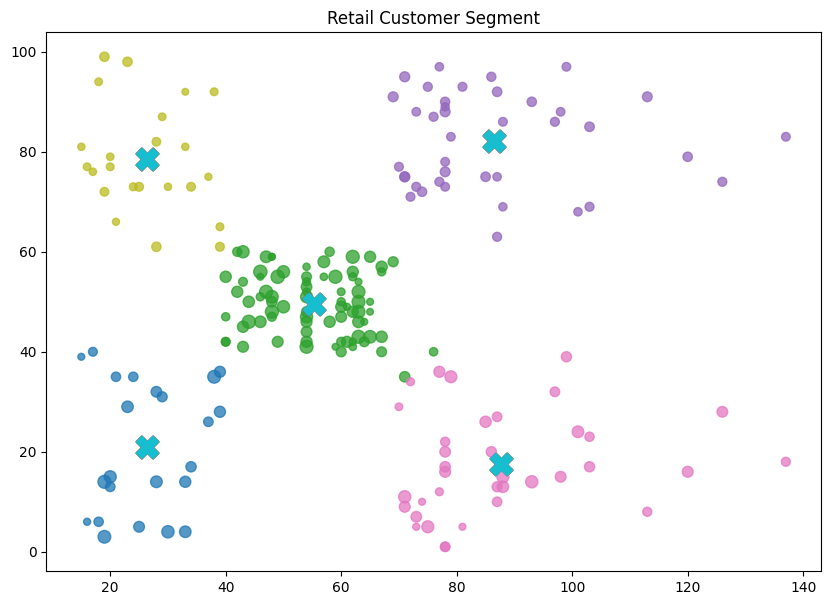

In [ ]:
plt.figure(figsize=(10, 7))

for cluster_id in sorted(df['clusters'].unique()):
  group = df[df['clusters'] == cluster_id]
  plt.scatter(group['Annual Income (k$)'], group['Spending Score (1-100)'], s=group['Age']*1.3, alpha=0.75,label=cluster_labels[cluster_id])
  plt.scatter(centers['Annual Income (k$)'],centers['Spending Score (1-100)'],s = 260 ,marker ='X', label='Centroids')
  plt.title("Retail Customer Segment")

In [ ]:
model_bundle = {
    'model': kmeans,
    'features': features,
    'cluster_labels': cluster_labels,
    'cluster_summary': summary.to_dict(orient='records'),
    'training_ranges':{'Age': [int(df['Age'].min()),int(df['Age'].max())],
    'Annual_Income': [int(df['Annual Income (k$)'].min()),int(df['Annual Income (k$)'].max())],
    'Spending_Score': [int(df['Spending Score (1-100)'].min()),int(df['Spending Score (1-100)'].max())]}
}

In [ ]:
#Try serializing the model and the metadata
joblib.dump(model_bundle,'model_bundle.joblib')

['model_bundle.joblib']

In [ ]:
saved = joblib.load('model_bundle.joblib')

example = [[30,90,85]] #Age - Income - Spending Score
cluster_id = saved['model'].predict(example)[0]

In [ ]:
cluster_id

np.int32(2)